# Этап 1. Данные и разведочный анализ

Набор Seoul Bike Sharing Demand из UCI. В нём число аренд велосипедов в Сеуле за каждый час с декабря 2017 по ноябрь 2018, погода и тип дня.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

raw = pd.read_csv("../data/raw/SeoulBikeData.csv", encoding="latin1")
print(raw.shape)
print(raw.isna().sum().sum(), "пропусков")
raw.head()

(8760, 14)
0 пропусков


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [2]:
raw.describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
Rented Bike Count,8760.0,704.6,645.0,0.0,191.0,504.5,1065.2,3556.0
Hour,8760.0,11.5,6.9,0.0,5.8,11.5,17.2,23.0
Temperature(°C),8760.0,12.9,11.9,-17.8,3.5,13.7,22.5,39.4
Humidity(%),8760.0,58.2,20.4,0.0,42.0,57.0,74.0,98.0
Wind speed (m/s),8760.0,1.7,1.0,0.0,0.9,1.5,2.3,7.4
Visibility (10m),8760.0,1436.8,608.3,27.0,940.0,1698.0,2000.0,2000.0
Dew point temperature(°C),8760.0,4.1,13.1,-30.6,-4.7,5.1,14.8,27.2
Solar Radiation (MJ/m2),8760.0,0.6,0.9,0.0,0.0,0.0,0.9,3.5
Rainfall(mm),8760.0,0.1,1.1,0.0,0.0,0.0,0.0,35.0
Snowfall (cm),8760.0,0.1,0.4,0.0,0.0,0.0,0.0,8.8


In [3]:
target = "Rented Bike Count"
print(raw["Functioning Day"].value_counts())
print("аренд в нерабочие дни:", raw.loc[raw["Functioning Day"] == "No", target].sum())
print("асимметрия цели:", round(raw[target].skew(), 2))

Functioning Day
Yes    8465
No      295
Name: count, dtype: int64
аренд в нерабочие дни: 0
асимметрия цели: 1.15


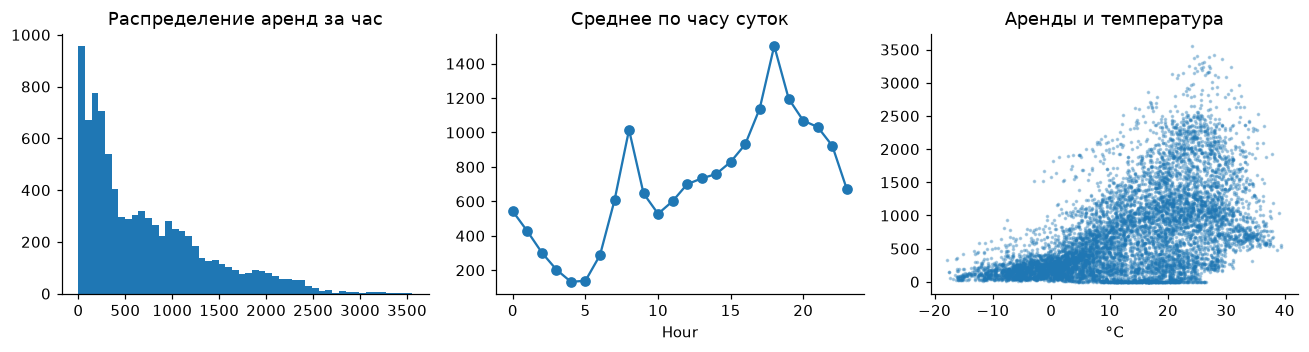

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.3))
axes[0].hist(raw[target], bins=50)
axes[0].set_title("Распределение аренд за час")
raw.groupby("Hour")[target].mean().plot(ax=axes[1], marker="o")
axes[1].set_title("Среднее по часу суток")
axes[2].scatter(raw["Temperature(°C)"], raw[target], s=2, alpha=.3)
axes[2].set_title("Аренды и температура")
axes[2].set_xlabel("°C")
plt.tight_layout()
plt.show()

In [5]:
raw.groupby("Seasons")[target].mean().round(0).sort_values()

Seasons
Winter     226.0
Spring     730.0
Autumn     820.0
Summer    1034.0
Name: Rented Bike Count, dtype: float64

**Выводы.**
- 8 760 строк, 14 столбцов, пропусков нет.
- 295 часов сервис не работал (`Functioning Day = No`), и аренд там 0. На этапе 2 эти строки убираем, предсказывать там нечего.
- Цель скошена вправо, асимметрия ≈ 1,15. Тихих часов много, пиковых мало.
- Спрос зависит от часа не по прямой. У него два пика, около 8:00 и около 18:00, и прямая их не опишет.
- С ростом температуры спрос растёт, но в жару рост замедляется. Летом аренд больше всего, зимой меньше всего.